In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import interpolate
from scipy.stats import gaussian_kde
import glob
import pickle
import matplotlib
import os
from os.path import normpath, basename

matplotlib.rcParams['font.size'] = 8.0
matplotlib.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'

In [47]:
Fs          = 3e4    #data sampling rate from orig
FS_ORIG     = 100    # natural behaviour video sampling rate
TimeHistory = 0.02   # 20ms pre-spike window (have not added post at all)
L           = int(TimeHistory * Fs)  # 600 samples, only consider length before 0

ANALYSIS_PATH = "./dataFolder/4_NaturalBehavior/"
BEH_PATH      = "./dataFolder/4_NaturalBehavior/ProboscisMovement-BehaviorData/"

In [9]:
# path for sta files 
compModel_path = "./dataFolder/3b_InDegrees/"

In [56]:
# get all the sta and nld files

sta_files = glob.glob(compModel_path + '*scaledSTA.csv')
nld_files = glob.glob(compModel_path + '*scaledNLD.csv')
ste_files = glob.glob(compModel_path + '*scaledSTE.csv')
sta_files
nld_files

['./dataFolder/3b_InDegrees\\m23_wn2_unit_1_scaledNLD.csv',
 './dataFolder/3b_InDegrees\\m29_wn2_unit_1_scaledNLD.csv',
 './dataFolder/3b_InDegrees\\m30_wn1_unit_1_scaledNLD.csv',
 './dataFolder/3b_InDegrees\\m31_wn2_unit_1_scaledNLD.csv',
 './dataFolder/3b_InDegrees\\m31_wn2_unit_2_scaledNLD.csv',
 './dataFolder/3b_InDegrees\\m31_wn2_unit_3_scaledNLD.csv']

In [ ]:
def predictSpikeProbability(novel_stim, sta, nld):
    # this function predicts spiking probability for a novel stimulus 
    # using prior constructed stan(mean position subtracted) and nld (as firing r)
    
    sta_length = len(sta)
    total_stimulus_length = len(novel_stim)
    
    proj = np.full(shape=len(novel_stim), np.nan, dtype=float)

    for strt_index in [sta_length:total_stimulus_length]:
        sliding_stim = novel_stim[strt_index-sta_length:strt_index]
        proj[strt_index] = np.dot(sta,sliding_stim)
    
#     fit nld to polynomial, find polyfit to np.dot
# 
    

In [69]:
for unit_path in sta_files[0:1]:
    
    unit_name = "_".join(basename(normpath(unit_path)).split('_')[0:4])
    sta_mean = pd.read_csv(unit_path)['sta_mean']
    nld = pd.read_csv([path for path in nld_files if unit_name in path][0])
    
    # normalize nld with average firing rate
    ste = pd.read_csv([path for path in ste_files if unit_name in path][0])
    total_spikes = len(ste)
    firing_rate = round(total_spikes/(10*30)) # 10s repeat 30 times == 300seconds
    
    nld.nld = nld.nld*firing_rate
    
    # center the sta because it is offseted
    sta_mean = sta_mean - np.mean(sta_mean) # ?this step shoudl have occured where we scale WN?
    
    # take only the segment pre-Spike
    sta_mean = sta_mean[:L]
    
    # use this computational model for all moth videos
    for beh_moth, upsampled in list(moth_data.items())[0:1]:
        predicted_Prob = predictSpikeProbability(upsampled, sta_mean, nld)

KeyError: slice(0, 1, None)

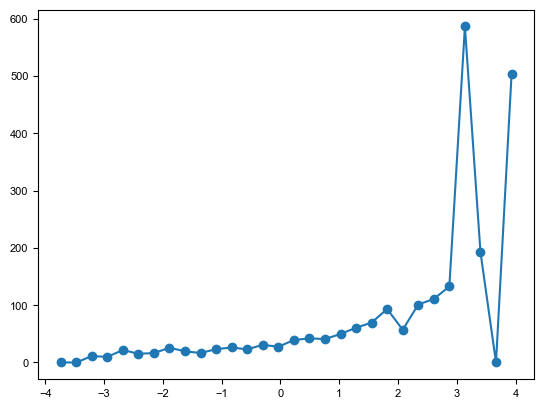

In [68]:
# plt.plot(sta_mean)
plt.plot(nld.bins, nld.nld, 'o-')

In [63]:
# wn_moth, unit_id = 'm30_wn1', 'unit_1'  
# unit_name = f"{wn_moth}_{unit_id}"

# sta_df  = pd.read_csv(f"{ANALYSIS_PATH}{wn_moth}_{unit_id}_STA.csv") #read in sta from saved file of sta values (analysis)
# sta_vec = sta_df['sta_mean'].to_numpy()[:L]  # take only the 600 pre-spike samples
# sta_vec = sta_vec - np.mean(sta_vec)          # remove offset 
# print(f"STA length: {len(sta_vec)} samples")
# print(f"STA mean after subtraction: {np.mean(sta_vec):.6f}")
# print(f"STA range: {sta_vec.min():.4f} to {sta_vec.max():.4f} degrees")

STA length: 600 samples
STA mean after subtraction: 0.000000
STA range: -6.7299 to 7.4538 degrees


In [16]:
# read in all the moth data

# Load the dictionary back from the file
with open('./dataFolder/4_NaturalBehavior/allmothMovement.pickle', 'rb') as file:
    moth_data = pickle.load(file)

print(f"data loaded from {len(moth_data)} with the following names {moth_data.keys()}")

data loaded from 8 with the following names dict_keys(['MV_m11_130802_errorAngle', 'MV_m13_130802_errorAngle', 'MV_m14_130806_errorAngle', 'MV_m1_130802_errorAngle', 'MV_m4_130802_errorAngle', 'MV_m5_130802_errorAngle', 'MV_m8_130805_errorAngle', 'MV_m9_130801_errorAngle'])


In [64]:
natural_stimulus = {}
for beh_moth, upsampled in moth_data.items():
    T    = len(upsampled)
    stim = np.full(T, np.nan)  # initialise with NaN
    
    # start at L (600) so first full 20ms window is available and its not predciting forward!
    # stop at T-L so last full 20ms window doesn't go beyond where there is no data!
    for t in range(L, T - L):
        stim_window = upsampled[t - L : t]          # 20ms window before t
        stim[t]     = np.dot(stim_window, sta_vec)  # dot product with STA
    
    natural_stimulus[beh_moth] = stim
    valid = stim[~np.isnan(stim)]
    print(f"{beh_moth}: {len(valid)} valid samples, range {valid.min():.2f} to {valid.max():.2f}")
    

print(f"\nExpected valid samples per moth: {T - 2*L}")

for beh_moth, stim in natural_stimulus.items():
    stim_df = pd.DataFrame({'natural_stimulus': stim})
    stim_df.to_csv(f"{BEH_PATH}{unit_name}_{beh_moth}_natural_stimulus.csv", index=False)
    print(f"Saved: {unit_name}_{beh_moth}_natural_stimulus.csv")

MV_m11_130802_errorAngle: 298500 valid samples, range -1078.30 to 1224.30
MV_m13_130802_errorAngle: 298500 valid samples, range -1972.30 to 1808.42
MV_m14_130806_errorAngle: 298500 valid samples, range -2227.69 to 2057.60
MV_m1_130802_errorAngle: 298500 valid samples, range -2359.22 to 4033.79
MV_m4_130802_errorAngle: 298500 valid samples, range -2016.59 to 1894.48
MV_m5_130802_errorAngle: 298500 valid samples, range -2823.25 to 2582.31
MV_m8_130805_errorAngle: 298500 valid samples, range -2848.93 to 2270.13
MV_m9_130801_errorAngle: 298500 valid samples, range -1892.78 to 1931.65

Expected valid samples per moth: 298500
Saved: m30_wn1_unit_1_MV_m11_130802_errorAngle_natural_stimulus.csv
Saved: m30_wn1_unit_1_MV_m13_130802_errorAngle_natural_stimulus.csv
Saved: m30_wn1_unit_1_MV_m14_130806_errorAngle_natural_stimulus.csv
Saved: m30_wn1_unit_1_MV_m1_130802_errorAngle_natural_stimulus.csv
Saved: m30_wn1_unit_1_MV_m4_130802_errorAngle_natural_stimulus.csv
Saved: m30_wn1_unit_1_MV_m5_130802

In [65]:
with open(f"{ANALYSIS_PATH}{wn_moth}_timeStamps.pickle", "rb") as f:
    data = pickle.load(f)

all_Units_aligned = data[0]
unit_tp           = np.concatenate(all_Units_aligned[unit_id], axis=0)
baseline_rate     = len(unit_tp) / (10.0 * 30)  # total spikes / 30 repeats x 10s
print(f"Total spikes: {len(unit_tp)}, baseline rate: {baseline_rate:.2f} spikes/s")


Total spikes: 10310, baseline rate: 34.37 spikes/s


In [66]:
# load saved prior_std - needed to normalize natural stimulus projections to NLD scale
prior_std = pd.read_csv(f"{ANALYSIS_PATH}{wn_moth}_{unit_id}_prior_std.csv")['prior_std'].values[0]
print(f"prior_std: {prior_std:.4f}")

# load saved NLD
nld_df   = pd.read_csv(f"{ANALYSIS_PATH}{wn_moth}_{unit_id}_NLD.csv")
nld_bins = nld_df['bins'].values
nld_vals = np.nan_to_num(nld_df['nld'].values)
print(f"NLD bins range: {nld_bins.min():.2f} to {nld_bins.max():.2f}")
print(f"NLD vals range: {nld_vals.min():.2f} to {nld_vals.max():.2f}")

prior_std: 630.8432
NLD bins range: -4.05 to 3.64
NLD vals range: 0.00 to 2.59


In [67]:
print("Natural stimulus ranges after normalization:")
for beh_moth, stim in natural_stimulus.items():
    valid = stim[~np.isnan(stim)] / prior_std
    print(f"  {beh_moth}: {valid.min():.2f} to {valid.max():.2f}")
print(f"\nNLD bins range: {nld_bins.min():.2f} to {nld_bins.max():.2f}")

Natural stimulus ranges after normalization:
  MV_m11_130802_errorAngle: -1.71 to 1.94
  MV_m13_130802_errorAngle: -3.13 to 2.87
  MV_m14_130806_errorAngle: -3.53 to 3.26
  MV_m1_130802_errorAngle: -3.74 to 6.39
  MV_m4_130802_errorAngle: -3.20 to 3.00
  MV_m5_130802_errorAngle: -4.48 to 4.09
  MV_m8_130805_errorAngle: -4.52 to 3.60
  MV_m9_130801_errorAngle: -3.00 to 3.06

NLD bins range: -4.05 to 3.64


In [68]:
stim_duration   = len(list(natural_stimulus.values())[0]) / Fs
bin_size        = 0.1
bin_edges       = np.arange(0, stim_duration + bin_size, bin_size)
predicted_rates = {}
spike_times     = {}

for beh_moth, stim in natural_stimulus.items():
    valid_mask  = ~np.isnan(stim)
    stim_clean  = stim[valid_mask] / prior_std  # normalize to NLD scale

    
    nld_novel = np.interp(stim_clean, nld_bins, nld_vals, left=0, right=0) #look up similarity of convolved to stim (see spike prob)

    # convert to spike probability per sample at 30kHz
    p_spike          = nld_novel * (baseline_rate / Fs)   # convert to spike probability per sample at 30kHz

    spikes           = np.where(np.random.rand(len(p_spike)) < p_spike)[0]
    spike_times_full = np.arange(len(stim))[valid_mask][spikes] / Fs
    spike_times[beh_moth] = spike_times_full

    
    counts, _      = np.histogram(spike_times_full, bins=bin_edges)
    predicted_rate = counts / bin_size  # spikes/s 
    predicted_rates[beh_moth] = predicted_rate
    print(f"  {beh_moth}: {predicted_rate.min():.1f}–{predicted_rate.max():.1f} spikes/s, {len(spikes)} spikes")

  MV_m11_130802_errorAngle: 10.0–100.0 spikes/s, 375 spikes
  MV_m13_130802_errorAngle: 0.0–100.0 spikes/s, 384 spikes
  MV_m14_130806_errorAngle: 0.0–90.0 spikes/s, 366 spikes
  MV_m1_130802_errorAngle: 0.0–90.0 spikes/s, 346 spikes
  MV_m4_130802_errorAngle: 0.0–100.0 spikes/s, 381 spikes
  MV_m5_130802_errorAngle: 0.0–80.0 spikes/s, 369 spikes
  MV_m8_130805_errorAngle: 0.0–70.0 spikes/s, 333 spikes
  MV_m9_130801_errorAngle: 0.0–90.0 spikes/s, 341 spikes


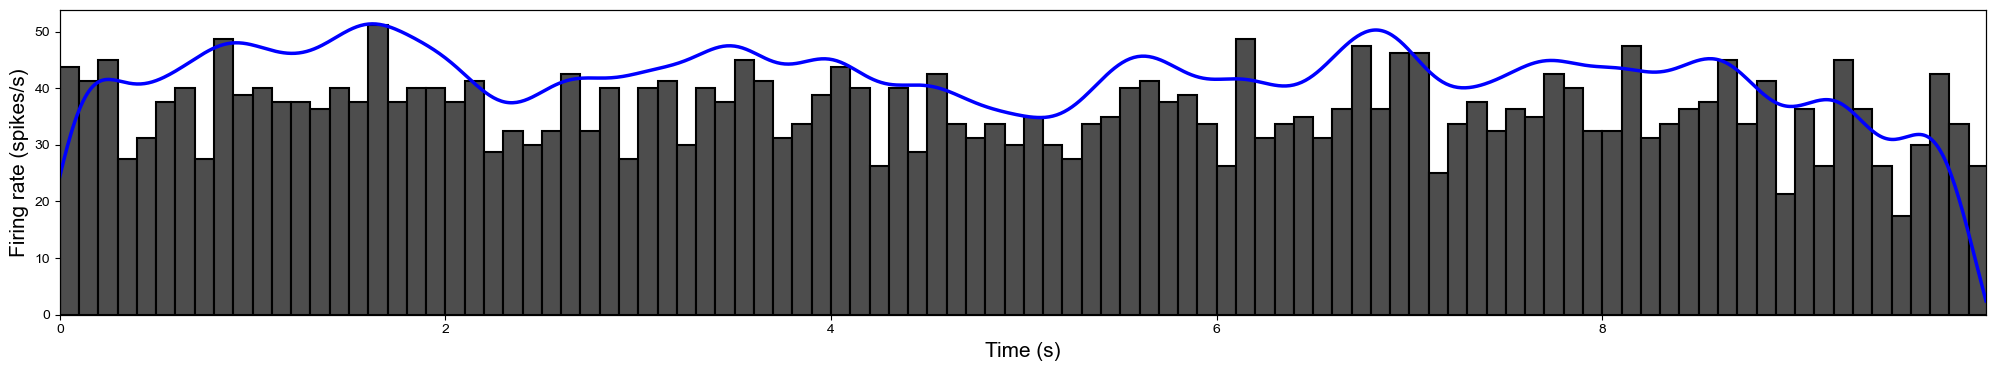

In [69]:
# mean predicted rate across all moths- they act as repeats
all_rates    = np.array(list(predicted_rates.values()))
mean_rate    = np.mean(all_rates, axis=0)

# same gaussian kde as original dataset
nonzero_mask = mean_rate > 0
kde_pred     = gaussian_kde(bin_edges[:-1][nonzero_mask],
                            weights=mean_rate[nonzero_mask], bw_method=0.06)
x_grid       = np.linspace(0, stim_duration, 1000)

fig, ax1 = plt.subplots(figsize=(20, 3.75))
ax2 = ax1.twinx()
ax1.bar(bin_edges[:-1], mean_rate, width=bin_size, align='edge',
        edgecolor='black', facecolor='0.3', linewidth=1.5)
ax2.plot(x_grid, kde_pred(x_grid), color='blue', linewidth=2.5)
ax1.set_xlim(0, stim_duration)
ax1.set_xlabel('Time (s)', fontsize=15)
ax1.set_ylabel('Firing rate (spikes/s)', fontsize=15)
ax1.tick_params(axis='both', labelsize=10)
ax2.set_yticks([])
plt.tight_layout()
plt.savefig(f"{BEH_PATH}{unit_name}_predicted_psth.pdf", bbox_inches='tight')
plt.show()

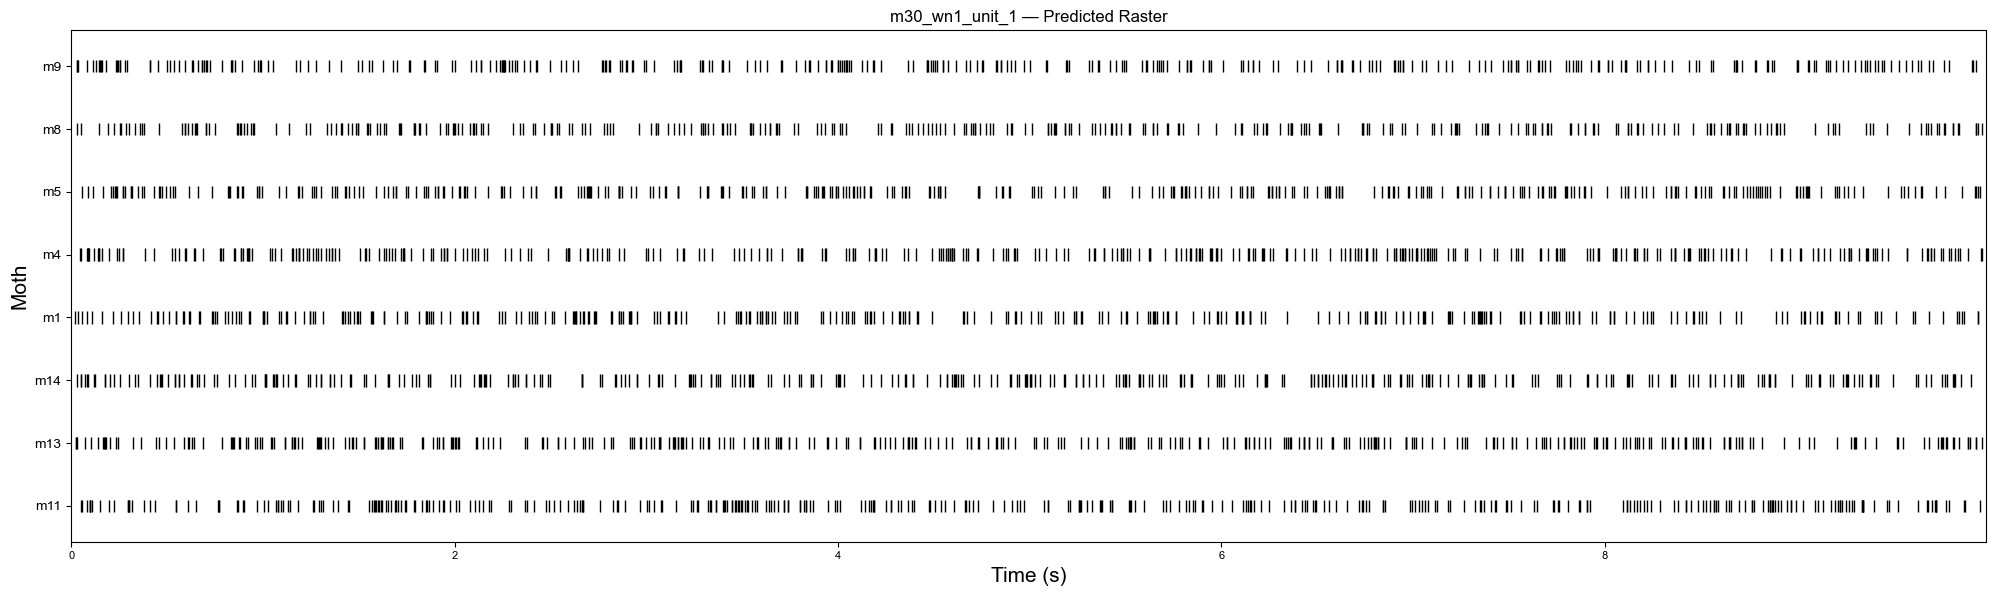

In [70]:
raster_data = [spike_times[m] for m in spike_times.keys()]  # list of spike arrays one per moth
moth_labels = [m.split("_")[1] for m in spike_times.keys()]  # just the moth number

fig, ax = plt.subplots(figsize=(20, 6))
ax.eventplot(raster_data, linelengths=0.2,
             lineoffsets=np.arange(1, len(raster_data) + 1),
             linewidth=1, color='black')
ax.set_xlim(0, stim_duration)
ax.set_yticks(np.arange(1, len(raster_data) + 1))
ax.set_yticklabels(moth_labels, fontsize=10)
ax.set_ylabel('Moth', fontsize=15)
ax.set_xlabel('Time (s)', fontsize=15)
ax.set_title(f'{unit_name} — Predicted Raster', fontsize=12)
plt.tight_layout()
plt.savefig(f"{BEH_PATH}{unit_name}_predicted_raster.pdf", bbox_inches='tight')
plt.show()
plt.close(fig)